In [1]:
import numpy as np
import pandas as pd
import os 
from pathlib import Path
print("현재 위치:", os.getcwd())

현재 위치: /Users/yuri.seo/Documents/GitHub/webnovel-pass-ab-test/notebooks


In [2]:
#데이터 불러오기

ROOT = Path.cwd().parent
DATA = ROOT / "data" / "clean"


coin_transactions = pd.read_csv(DATA / "coin_transactions.csv.gz",parse_dates=['txn_at'])
daily_reading = pd.read_csv(DATA / "daily_reading.csv.gz",parse_dates = ['read_date'])
exposures = pd.read_csv(DATA / "exposures.csv.gz",parse_dates = ['exposed_at'])
subscription_events = pd.read_csv(DATA / "subscription_events.csv.gz",parse_dates = ['event_at'])
titles = pd.read_csv(DATA / "titles.csv.gz")
users = pd.read_csv(DATA / "users.csv.gz",parse_dates = ['signup_date'])



# 각 테이블 정보 확인을 위해 딕셔너리 생성
table_info = {"coin_transactions":coin_transactions,
      "daily_reading":daily_reading,
     "exposures":exposures,
     "subscription_events":subscription_events,
     "titles":titles,
     "users":users}

for key, val in table_info.items():
    print(key, val.shape)


coin_transactions (823238, 6)
daily_reading (1859866, 6)
exposures (314922, 4)
subscription_events (60367, 5)
titles (6300, 4)
users (314922, 9)


# 전환율 확인

In [3]:
# variant별 전환율 구하기 

# base 테이블 만들기
# 전체 유저 | variant | started_trial | 결제 여부 (converted)

base = table_info["users"][["user_id"]]

base = base.merge(
    table_info["exposures"][["user_id","variant"]],
    on = "user_id",
    how = "left"
)


# base에 trial True =1 False = 0 으로 추가하기. 

# events로 먼저 정리 
events = table_info["subscription_events"].copy()

events["start_trial"] = (events["event_type"] == 'trial_start').astype(int)
events["converted"] = (events["event_type"] == 'payment').astype(int)
events

# user별 그룹화 
user_events = events.groupby("user_id")[["start_trial","converted"]].max().reset_index()

# Join
base = base.merge(
    user_events[["user_id","start_trial","converted"]],
    on = "user_id",
    how = "left"
)

# 결측치 0으로 변환 
base[["start_trial","converted"]] = base[["start_trial","converted"]].fillna(0).astype(int)

len(base)


# 각 그룹별 전환율 구하기
result_st = base.groupby("variant")["start_trial"].mean()                                       ## 체험율
result_st_convert = base.loc[base["start_trial"]==1].groupby("variant")["converted"].mean()     ## 체험시작 기준 전환율 (start_trial)
result_e_convert = base.groupby("variant")["converted"].mean()                                  ## 노출자 기준 전환율 (exposed)
result_user_cnt = base.groupby("variant")["user_id"].nunique()                                ## 전체 유저 수
result_st_cnt = base.groupby("variant")["start_trial"].sum()                                    ## 체험 유저 수
result_convert_cnt = base.groupby("variant")["converted"].sum()                                 ## 구매 유저 수


result_d = pd.DataFrame({
    "노출 유저 수" : result_user_cnt,
    "체험 유저 수" : result_st_cnt,
    "구매 유저 수" : result_convert_cnt,
    "체험 시작률"  : result_st,
    "노출 기준 전환율" : result_e_convert,
    "체험 시작 기준 전환율" : result_st_convert
})
result_d = result_d.T
result_d


variant,A,B
노출 유저 수,157461.000000,157461.000000
체험 유저 수,12323.000000,13805.000000
구매 유저 수,3602.000000,3977.000000
체험 시작률,0.078261,0.087673
노출 기준 전환율,0.022876,0.025257
체험 시작 기준 전환율,0.292299,0.288084


In [4]:
# ── 비율 행만 %로 바꾸기 ──
rate_rows = ["체험 시작률", "노출 기준 전환율", "체험 시작 기준 전환율"]
count_rows = ["노출 유저 수", "체험 유저 수", "구매 유저 수"]

result_d.loc[rate_rows] = result_d.loc[rate_rows] * 100

# ── 차이와 상대 uplift ──
# 절대 차이: B - A  (비율 행은 %p, 인원 행은 명)
result_d["차이(B-A)"] = result_d["B"] - result_d["A"]

# 상대 uplift: (B - A) / A × 100  → 비율 행에만 의미가 있음
result_d["상대 uplift(%)"] = (result_d["B"] - result_d["A"]) / result_d["A"] * 100
result_d.loc[count_rows, "상대 uplift(%)"] = np.nan   # 인원 수의 uplift는 의미 없으니 비움

# ── 보기 좋게 반올림 ──
result_d = result_d.round(2)
result_d

variant,A,B,차이(B-A),상대 uplift(%)
노출 유저 수,157461.00,157461.00,0.00,NaN
체험 유저 수,12323.00,13805.00,1482.00,NaN
구매 유저 수,3602.00,3977.00,375.00,NaN
체험 시작률,7.83,8.77,0.94,12.03
노출 기준 전환율,2.29,2.53,0.24,10.41
체험 시작 기준 전환율,29.23,28.81,-0.42,-1.44


### 라운드 1 결과: 첫인상

**관찰**
- 체험 시작률: A 7.83% vs B 8.77% → B가 0.94%p 높음 (상대 +12.0%)
- 노출 기준 전환율: A 2.29% vs B 2.53% → B가 0.24%p 높음 (상대 +10.4%)
- 체험 시작 기준 전환율: A 29.23% vs B 28.81% → A가 0.42%p 높음 (상대 -1.4%)

**첫인상**
- 어떤 전환율을 보느냐에 따라 우세한 그룹이 바뀜
- 노출 기준으로는 B가 나아 보이고, 체험 시작 기준으로는 A가 근소하게 나아 보임
- 세 지표 중 차이가 가장 큰 것은 체험 시작률 (상대 +12.0%)

**기준마다 결과가 다른 이유 (가설)**
- 노출 기준 전환율 = 체험 시작률 × 체험 시작 기준 전환율
- B는 "14일 무료" 문구로 체험을 더 많이 끌어왔고(체험 시작률 ↑), 그중 결제로 이어진 비율은 A와 비슷하거나 조금 낮음
- 그 결과 노출 기준으로는 B가 앞서고, 체험 시작 기준으로는 A가 앞섬

**남은 의문 → 라운드 2·3에서 확인**
1. 차이가 모두 1%p 미만. 우연히 생긴 차이일 가능성은? → 통계 검정 필요
2. 노출 유저 수가 A, B 정확히 같음. 배정이 제대로 이뤄졌나? → SRM 점검
3. 두 그룹은 실험 전에 비슷한 사람들이었나? → 사전 균형 점검
4. B가 체험을 더 많이 끌어왔다면, B의 체험 시작자에는 A라면 체험하지 않았을 사람이 섞여 있음. A·B의 체험 시작자를 그대로 비교해도 공정한가? → 선택 편향 점검
5. 출시 판단에는 어떤 전환율을 써야 하나? 각 지표는 어떤 질문에 답하는 숫자인가?

## 라운드 2. 실험 점검: 이 실험을 믿을 수 있는가

### 왜 점검부터 하는가
- 라운드 1에서 본 차이를 "B(14일 체험) 때문"이라고 말하려면, 두 그룹이 체험 기간 외에는 같은 조건이어야 함
- 이 전제가 깨져 있으면 검정을 아무리 정교하게 해도 결론을 신뢰할 수 없음
- 따라서 검정(라운드 3) 전에 아래 두 가지를 먼저 확인

| 점검 | 질문 | 실패 시 |
| --- | --- | --- |
| SRM | 계획한 비율(50:50)대로 배정됐는가 | 배정 시스템·로그 오류 의심 → 결과 전체 보류 |
| 사전 균형 | 실험 전 행동이 두 그룹에서 비슷한가 | 처음부터 다른 집단 → 차이의 원인을 B로 볼 수 없음 |

---

### 2-1. SRM (Sample Ratio Mismatch)

**질문**
- 50:50 배정이었다면 현재 관찰된 인원 비율이 나올 만한가

**고민: A·B 인원이 정확히 같은데 검정이 필요한가**
- 점검은 숫자를 보고 할지 말지 정하는 것이 아니라 항상 같은 절차로 수행
- 다른 실험에서 157,461 vs 156,890처럼 어긋났을 때 "이 정도면 괜찮은가"를 판단하는 기준이 검정
- 정확히 동일한 인원은 무작위 배정에서 흔하지 않음 (15만 명씩 나누면 보통 수백 명 차이 발생)
  - 실무라면 강제 균등 배정 방식인지 확인할 대상
  - SRM은 비율이 어긋난 것을 찾는 검정이므로 이 경우 실패 사유는 아님
  - 본 데이터에서는 생성 과정에서 우연히 일치한 것으로 판단

**후보 방법**

| 방법 | 내용 | 판단 |
| --- | --- | --- |
| 카이제곱 적합도 검정 | 관찰 인원과 기대 인원(전체의 50%씩) 비교 | ✅ 채택. SRM 점검의 표준 방법, 그룹이 3개 이상이어도 동일하게 적용 가능 |
| 이항 검정 | "A일 확률 0.5"인 시행 결과로 간주 | △ 두 그룹에서는 결과가 사실상 동일. 확장성 때문에 카이제곱 선택 |
| 비율 눈으로 확인 | 50.1% vs 49.9%면 괜찮다고 판단 | ✗ 판단 기준이 없음. 31만 명 규모에서는 0.3%p 차이도 이상 신호일 수 있음 |

**판단 기준: p < 0.001이면 SRM**
- 일반적인 0.05보다 엄격하게 설정 (실험 설계서 7장)
- SRM은 "실험 전체를 버린다"는 무거운 결정 → 우연한 흔들림으로 실험을 버리는 손실이 큼
- 실제 배정 오류는 보통 수천 명 단위로 어긋나므로 엄격한 기준으로도 충분히 탐지됨

---

### 2-2. 사전 균형 (Pre-experiment balance)

**질문**
- 실험 전에 이미 정해진 값들이 두 그룹에서 비슷한가
- 실험 전 값은 B의 영향을 받을 수 없으므로, 여기서 차이가 크면 배정 자체가 치우쳤다는 신호

**비교 대상**

| 유형 | 컬럼 |
| --- | --- |
| 숫자 | pre30_serial_reads, pre30_completed_reads, pre30_free_reads, pre30_coin_spend |
| 범주 | age_group, acquisition_channel, preferred_genre, platform |

**고민: t-검정으로 평균을 비교하면 되지 않나**
- 표본이 약 31만 명으로 매우 큼
- 표본이 크면 실질적으로 무의미한 작은 차이도 p-value가 0.05 아래로 떨어짐
  - 예: 실험 전 30일 열람이 A 45.1화, B 45.3화여도 "유의한 차이"로 나올 수 있음
  - 그렇다고 두 그룹이 다른 집단이라고 보기는 어려움
- 따라서 "차이가 있는가(p-value)"보다 "차이가 얼마나 큰가(효과 크기)"로 판단

**후보 방법**

| 방법 | 묻는 것 | 판단 |
| --- | --- | --- |
| t-검정 p-value | 차이가 0인가 | △ 표본이 크면 사소한 차이도 유의하게 나옴. 참고용 |
| 표준화 평균 차이 (SMD) | 차이가 분포 폭에 비해 얼마나 큰가 | ✅ 숫자 컬럼에 채택 |
| 그룹별 비율 비교 + 카이제곱 독립성 검정 | 범주 분포가 그룹마다 다른가 | ✅ 범주 컬럼에 채택. 비율 차이를 함께 확인 |

**SMD (Standardized Mean Difference)**
- SMD = (B 평균 − A 평균) ÷ 합친 표준편차
- 합친 표준편차 = √((A 분산 + B 분산) / 2)
- 단위가 사라져 열람 회차·결제 금액처럼 단위가 다른 컬럼을 같은 기준으로 비교 가능
- 판단 기준: |SMD| < 0.1이면 균형

**범주 컬럼 확인 방법**
- 그룹별 비율: crosstab(행 = variant, normalize = "index")로 그룹마다 합이 1이 되도록 구성
- 검정: 비율이 아닌 인원수 교차표로 카이제곱 독립성 검정
- 표본이 큰 만큼 p-value보다 비율 차이(%p) 크기를 함께 보고 판단

---

### 체크포인트
- [ ] SRM 카이제곱 p ≥ 0.001
- [ ] 숫자 컬럼 4개 |SMD| < 0.1
- [ ] 범주 컬럼 그룹 간 비율 차이 확인

In [5]:
from scipy.stats import chisquare

# ── 설정: 배정 비율과 판단 기준 (실험 설계서 7장) ──
ALLOCATION = {"A": 0.5, "B": 0.5}    # 계획한 배정 비율
SRM_ALPHA = 0.001                    # SRM 판단 기준 (일반 기준 0.05보다 엄격)

# ── 관찰 인원 vs 기대 인원 ──
observed = base["variant"].value_counts().reindex(ALLOCATION.keys())   # A, B 순서 고정
total = observed.sum()
expected = pd.Series({g: total * r for g, r in ALLOCATION.items()})

# ── 카이제곱 적합도 검정 ──
srm = chisquare(f_obs=observed, f_exp=expected)

# ── 결과 표 ──
srm_table = pd.DataFrame({
    "관찰 인원": observed,
    "기대 인원": expected,
    "관찰 비율(%)": (observed / total * 100).round(3),
    "계획 비율(%)": pd.Series(ALLOCATION) * 100,
})
display(srm_table)

# ── 판단 ──
print(f"카이제곱 통계량: {srm.statistic:.4f}")
print(f"p-value: {srm.pvalue:.4f}")

if srm.pvalue < SRM_ALPHA:
    print(f"⚠️ SRM 발생 (p < {SRM_ALPHA}) → 배정 오류 의심, 결과 해석 보류")
else:
    print(f"✅ SRM 없음 (p ≥ {SRM_ALPHA}) → 계획한 비율대로 배정됨")

,관찰 인원,기대 인원,관찰 비율(%),계획 비율(%)
A,157461,157461.0,50.0,50.0
B,157461,157461.0,50.0,50.0


카이제곱 통계량: 0.0000
p-value: 1.0000
✅ SRM 없음 (p ≥ 0.001) → 계획한 비율대로 배정됨


**SRM 결과**
- A 157,461명, B 157,461명 (50.000% : 50.000%)
- 카이제곱 통계량 0.0, p = 1.0 → SRM 없음
- 참고: 인원이 정확히 일치하는 것은 무작위 배정에서 드문 경우. 실무라면 강제 균등 배정 여부를 확인할 대상이나, 본 데이터는 생성 과정의 우연한 일치로 판단

In [6]:
# ── 비교할 컬럼과 판단 기준 ──
NUM_COLS = ["pre30_serial_reads", "pre30_completed_reads",
            "pre30_free_reads", "pre30_coin_spend"]                      # 숫자: SMD로 비교
CAT_COLS = ["age_group", "acquisition_channel", "preferred_genre", "platform"]  # 범주: 비율 차이로 비교
SMD_THRESHOLD = 0.1                                                        # |SMD| < 0.1 이면 균형

# ── 배정 정보(base)에 실험 전 정보 붙이기 ──
# platform은 exposures에, 나머지는 users에 있음
balance_df = (
    base[["user_id", "variant"]]
    .merge(users[["user_id"] + NUM_COLS + ["age_group", "acquisition_channel", "preferred_genre"]],
           on="user_id", how="left")
    .merge(exposures[["user_id", "platform"]], on="user_id", how="left")
)

# 확인: 행 수 유지, 결측 없음
print(f"행 수: {len(balance_df):,}  /  결측: {balance_df.isna().sum().sum()}")

행 수: 314,922  /  결측: 0


In [7]:
from scipy.stats import ttest_ind

group_a = balance_df[balance_df["variant"] == "A"]
group_b = balance_df[balance_df["variant"] == "B"]

rows = []
for col in NUM_COLS:
    # 합친 표준편차: 두 그룹 분산의 평균에 제곱근
    pooled_sd = np.sqrt((group_a[col].var() + group_b[col].var()) / 2)
    smd = (group_b[col].mean() - group_a[col].mean()) / pooled_sd

    # 참고용 t-검정 (표본이 커서 판단 기준으로는 쓰지 않음)
    t_p = ttest_ind(group_a[col], group_b[col], equal_var=False).pvalue

    rows.append({
        "컬럼": col,
        "A 평균": group_a[col].mean(),
        "B 평균": group_b[col].mean(),
        "SMD": smd,
        "t-검정 p (참고)": t_p,
        "균형": "OK" if abs(smd) < SMD_THRESHOLD else "⚠️",
    })

num_balance = pd.DataFrame(rows).round(4)
num_balance

,컬럼,A 평균,B 평균,SMD,t-검정 p (참고),균형
0,pre30_serial_reads,52.0084,52.0659,0.0015,0.6726,OK
1,pre30_completed_reads,68.2905,68.3620,0.0008,0.8240,OK
2,pre30_free_reads,20.9136,20.8087,-0.0061,0.0855,OK
3,pre30_coin_spend,3162.4313,3157.3317,-0.0007,0.8551,OK


In [8]:
from scipy.stats import chi2_contingency

rows = []
for col in CAT_COLS:
    counts = pd.crosstab(balance_df["variant"], balance_df[col])                         # 인원수 (검정용)
    share = pd.crosstab(balance_df["variant"], balance_df[col], normalize="index") * 100  # 그룹별 비율 (%)

    # 범주마다 B-A 비율 차이를 구하고, 그중 가장 큰 차이
    max_diff = (share.loc["B"] - share.loc["A"]).abs().max()

    rows.append({
        "컬럼": col,
        "범주 수": counts.shape[1],
        "최대 비율 차이(%p)": max_diff,
        "카이제곱 p": chi2_contingency(counts).pvalue,
    })

cat_balance = pd.DataFrame(rows).round(4)
cat_balance

,컬럼,범주 수,최대 비율 차이(%p),카이제곱 p
0,age_group,4,0.0908,0.9229
1,acquisition_channel,4,0.2820,0.4402
2,preferred_genre,5,0.1111,0.8111
3,platform,2,0.1556,0.2243


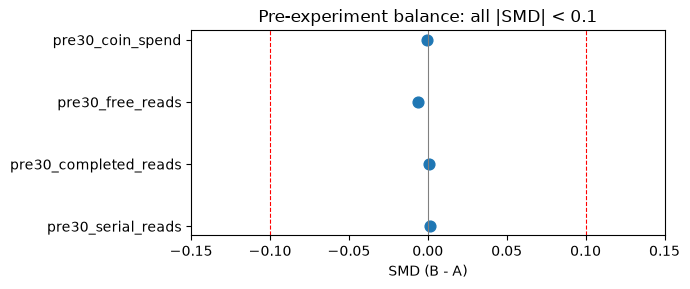

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(num_balance["SMD"], num_balance["컬럼"], s=60)
ax.axvline(0, color="gray", linewidth=0.8)
ax.axvline(SMD_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
ax.axvline(-SMD_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("SMD (B - A)")
ax.set_title("Pre-experiment balance: all |SMD| < 0.1")
plt.tight_layout()
plt.show()

**사전 균형 결과**
- 숫자 컬럼 4개: 모든 |SMD| < 0.01 (기준 0.1) → 균형
- 범주 컬럼 4개: 그룹 간 비율 차이 최대 0.28%p (acquisition_channel), 카이제곱 p 모두 > 0.05 → 균형
- 참고: t-검정 p도 모두 0.05 이상이나, 표본이 커서 판단 기준으로는 SMD를 사용

### 라운드 2 결론
- [x] SRM 없음 (p = 1.0)
- [x] 사전 균형 확인 (|SMD| < 0.1, 범주 비율 차이 < 0.3%p)
- → 배정은 정상적으로 이뤄졌고, 두 그룹은 실험 전 행동이 같은 집단으로 판단

**라운드 1 의문 중**
- 해결: ② 배정이 제대로 됐는가 → SRM 없음 / ③ 실험 전에 비슷한 사람들이었나 → 균형 확인
- 남음: ① 차이가 우연인가 / ④ 체험 시작자 비교의 선택 편향 / ⑤ 어떤 전환율로 판단할 것인가 → 라운드 3

## 라운드 3. 재검토: 첫인상은 우연인가, 그리고 어떤 기준으로 봐야 하는가

### 라운드 2까지 확인된 것
- 배정 정상 (SRM 없음), 두 그룹은 실험 전 동일한 집단 (사전 균형)
- 따라서 실험 이후의 차이는 체험 기간(7일 vs 14일)의 영향으로 볼 수 있는 상태

### 이번 라운드의 질문
1. 라운드 1에서 본 전환율 차이는 우연으로 설명되는가
2. 체험 시작률이 다르다면, 체험 시작자끼리 비교하는 것이 공정한가 (선택 편향)
3. 출시 판단에는 어떤 전환율을 써야 하는가

---

### 3-1. 검정 방법 선택

**지표 특성**
- 전환 여부는 유저마다 0 또는 1 → 두 그룹의 비율 비교 문제

**후보 방법**

| 방법 | 판단 |
| --- | --- |
| 두 비율 z-검정 | ✅ 채택. 그룹당 1만 명 이상으로 정규근사 충분, 차이의 방향·크기를 바로 제시 |
| 카이제곱 독립성 검정 | △ 2×2에서는 z-검정과 p-value 동일. 차이의 크기·신뢰구간을 따로 구해야 함 |
| Fisher 정확 검정 | ✗ 표본이 작을 때 쓰는 방법. 본 실험 규모에서는 불필요 |
| 로지스틱 회귀 | 라운드 5(세그먼트 분석)에서 사용 |

**p-value만으로 판단하지 않는 이유**
- p-value는 "차이가 0인가"만 알려줌. 차이가 얼마나 큰지는 알려주지 않음
- 신뢰구간을 함께 제시해 "진짜 차이가 있을 법한 범위"를 확인
- 신뢰구간이 0을 포함하면 차이가 없다는 가능성을 배제할 수 없음
- 신뢰구간을 실험 설계 시 정한 MDE(2%p)와 비교해 사업적으로 의미 있는 크기인지 판단

---

### 3-2. 선택 편향 점검

**문제 제기**
- 소개 화면에 "7일 무료" / "14일 무료"가 노출됨 → 체험 기간 자체가 체험 시작 여부에 영향 가능
- B가 체험을 더 많이 끌어왔다면, B 체험 시작자에는 "7일이었다면 체험하지 않았을 사람"이 섞여 있음
- 이 경우 A·B 체험 시작자는 같은 집단이 아님 → 체험 시작자끼리 비교하면 배정의 무작위성이 깨짐

**확인 방법**
- 체험 시작률을 두 비율 z-검정으로 비교
- 유의한 차이가 있으면 선택 편향 가능성 → 노출자 기준 전환율로 결론이 같은지 확인 (실험 설계서 7장 4번)

---

### 3-3. 두 전환율이 답하는 질문

| 지표 | 분모 | 답하는 질문 | 무작위 배정 유지 |
| --- | --- | --- | --- |
| 체험 시작자 기준 전환율 | 체험 시작자 | 체험을 시작한 사람 중 몇 %가 결제하는가 | ✗ 배정 이후 행동(체험 시작)으로 분모를 거름 |
| 노출자 기준 전환율 | 소개 화면 노출자 전원 | B로 출시하면 노출된 유저 중 결제하는 사람이 늘어나는가 | ✅ 배정된 전원을 그대로 비교 |

- 노출자 기준은 배정된 사람 전원을 비교하므로 무작위 배정의 공정성이 그대로 유지됨
- 실무에서는 이를 ITT(Intention-To-Treat, 배정 기준 분석)라고 부름
- 체험 시작자 기준은 "체험 이후 경험의 질"을 진단하는 보조 지표로 활용

In [10]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ALPHA = 0.05      # 유의수준
MDE = 2.0         # 최소 검출 효과 (%p, 실험 설계서 6장)

def two_prop_test(name, success_a, n_a, success_b, n_b):
    """두 그룹 비율 차이(B - A)의 z-검정과 95% 신뢰구간"""
    rate_a, rate_b = success_a / n_a, success_b / n_b

    # z-검정 (B, A 순서로 넣어야 z가 B - A 방향)
    z, p = proportions_ztest([success_b, success_a], [n_b, n_a])

    # 차이(B - A)의 95% 신뢰구간
    ci_low, ci_high = confint_proportions_2indep(success_b, n_b, success_a, n_a,
                                                 method="wald", alpha=ALPHA)

    return {
        "지표": name,
        "A(%)": rate_a * 100,
        "B(%)": rate_b * 100,
        "차이(%p)": (rate_b - rate_a) * 100,
        "상대 uplift(%)": (rate_b - rate_a) / rate_a * 100,
        "95% CI 하한(%p)": ci_low * 100,
        "95% CI 상한(%p)": ci_high * 100,
        "z": z,
        "p-value": p,
        "유의": "OK" if p < ALPHA else "-",
    }

In [11]:
# ── 그룹별 인원 ──
exposed = base.groupby("variant")["user_id"].count()                                # 노출자
trial   = base.groupby("variant")["start_trial"].sum()                              # 체험 시작자
paid    = base.groupby("variant")["converted"].sum()                                # 결제자

# ── 지표 3개를 같은 함수로 검정 ──
test_results = pd.DataFrame([
    two_prop_test("체험 시작 기준 전환율", paid["A"], trial["A"],   paid["B"], trial["B"]),
    two_prop_test("체험 시작률",          trial["A"], exposed["A"], trial["B"], exposed["B"]),
    two_prop_test("노출 기준 전환율",      paid["A"], exposed["A"], paid["B"], exposed["B"]),
]).set_index("지표")

test_results.round(3)

,A(%),B(%),차이(%p),상대 uplift(%),95% CI 하한(%p),95% CI 상한(%p),z,p-value,유의
지표,,,,,,,,,
체험 시작 기준 전환율,29.230,28.808,-0.421,-1.442,-1.524,0.681,-0.749,0.454,-
체험 시작률,7.826,8.767,0.941,12.026,0.749,1.134,9.574,0.000,OK
노출 기준 전환율,2.288,2.526,0.238,10.411,0.131,0.345,4.360,0.000,OK


### 라운드 3 결과

**3-1. 주요 지표 (체험 시작 기준 전환율)**
- A 29.23% vs B 28.81%, 차이 -0.42%p, 95% CI [-1.52, +0.68], p = 0.45
- 신뢰구간이 0을 포함 → 우연으로 설명 가능한 차이, 유의하지 않음
- 신뢰구간 전체가 MDE(±2%p) 안에 있음 → 설계 시 의미 있다고 본 크기의 차이는 없다고 판단

**3-2. 선택 편향 점검 (체험 시작률)**
- A 7.83% vs B 8.77%, 차이 +0.94%p (상대 +12.0%), p < 0.001
- "14일 무료" 문구가 체험 시작을 유의하게 늘림
- → A·B 체험 시작자는 같은 집단이 아님. 체험 시작자 기준 비교에는 선택 편향이 존재

**3-3. 노출 기준 전환율 (배정 기준 비교)**
- A 2.29% vs B 2.53%, 차이 +0.24%p (상대 +10.4%), 95% CI [+0.13, +0.35], p < 0.001
- 배정된 전원을 비교하는 지표에서는 B가 유의하게 높음

**종합**
- 체험 시작자 기준: 차이 없음 / 노출자 기준: B 우세 → 기준에 따라 결론이 다름
- 노출자 기준이 무작위 배정을 유지하는 비교이므로 "B가 결제자 수를 늘린다"는 결론이 더 신뢰할 만함
- 증가 경로: B는 체험 시작자를 늘렸고(+12%), 체험 후 결제 비율은 A와 차이가 없음 → 결제자 수 증가

**실험 설계에 대한 회고**
- 설계 시 주요 지표를 체험 시작자 기준으로 정했으나, 체험 기간 문구가 체험 시작에 영향을 주는 구조에서는 선택 편향에 취약
- 설계서 7장의 선택 편향 확인 절차 덕분에 이를 발견할 수 있었음
- 다음 설계에서는 노출자 기준 전환율을 주요 지표로 두는 것이 적절

**남은 의문 → 라운드 4**
- 결제자 수는 늘었지만, B 결제자가 빨리 해지하거나 코인 결제가 줄었다면 매출은 오히려 줄 수도 있음
- 전환율만으로 출시를 결정해도 되는가 → 가드레일(해지율, 60일 매출) 확인 필요

## 라운드 4. 가드레일: 결제자가 늘어난 대가로 망가진 것은 없는가

### 라운드 3까지의 결론
- 노출자 기준 전환율은 B가 유의하게 높음 (+0.24%p, 상대 +10.4%) → B는 결제자 수를 늘림

### 이번 라운드의 질문
- 늘어난 결제자가 금방 해지한다면?
- 패스 때문에 코인 결제가 줄었다면? (잠식효과)
- 결국 매출은 늘었는가, 줄었는가

### 가드레일 지표 (실험 설계서 5장)

| 지표 | 정의 | 판단 기준 |
| --- | --- | --- |
| 첫 달 해지율 | 유료 전환자 중 2회차 결제 전 해지 비율 | 3%p 이상 악화 시 출시 보류 (설계서 8장) |
| 60일 총매출 | 체험 시작자 1인당 60일간 패스 + 코인 결제액 | 유의한 감소 시 A 유지 (설계서 8장) |

---

### 4-1. 유저 표에 컬럼 추가

**첫 달 해지 정의 방법**
- 설계서 정의: 유료 전환자 중 2회차 결제 전에 해지
- 관찰 기간 60일 안에 2회차 결제일이 모두 포함됨 (A: D7·D37, B: D14·D44)
- 따라서 "전환했는데 결제가 1회뿐"인 유저 = 첫 달 해지자
- 결제 횟수로 정의한 뒤, 실제 cancel 이벤트와 교차 확인

**매출 컬럼**
- pass_rev: 유저별 결제 금액 합계
- coin_rev: 유저별 코인 수 합계 × 100원
- total_rev: pass_rev + coin_rev
- 기록이 없으면 0원 (결제·코인 사용을 하지 않은 것)
- 코인·열람 기록은 데이터 생성 시 체험 시작 후 60일 이내만 수집됨 → 별도 기간 필터 불필요

---

### 4-2. 첫 달 해지율 검정
- 비율 지표 → 라운드 3의 두 비율 z-검정 함수 재사용
- 분모: 유료 전환자

---

### 4-3. 60일 총매출 검정

**데이터 특성**
- 패스 매출은 결제자만 발생 (체험 시작자의 약 70%는 0원)
- 코인 매출은 소수 헤비 유저에게 몰림
- → 총매출은 0원은 드물지만 오른쪽 꼬리가 긴 분포

**후보 방법**

| 방법 | 비교 대상 | 판단 |
| --- | --- | --- |
| Welch t-검정 | 평균 | △ 표본이 커서 평균 비교에는 사용 가능. 교차 확인용 |
| 부트스트랩 | 평균 (분포 가정 없음) | ✅ 채택 (설계서 7장). 리샘플링으로 신뢰구간을 직접 구함 |
| Mann-Whitney U | 순위·분포 위치 | ✗ 평균이 아닌 "대체로 누가 더 큰가"를 비교. 매출 판단에는 평균(총액)이 필요 |
| 로그 변환 후 t-검정 | 기하평균 | ✗ 질문이 바뀜. 0원 처리 문제도 있음 |

**평균을 보는 이유**
- 회사 매출 = 1인당 평균 매출 × 유저 수 → 출시 판단에 필요한 것은 평균

**부트스트랩 원리**
- 각 그룹에서 같은 인원을 복원 추출(중복 허용)로 다시 뽑아 평균 차이를 계산
- 이를 2,000번 반복해 평균 차이의 분포를 만들고, 가운데 95% 구간을 신뢰구간으로 사용
- 정규분포 가정 없이 데이터 자체로 불확실성을 추정

**시행착오 포인트**
- t-검정과 부트스트랩을 모두 실행해 결과가 일치하는지 확인
- 일치하면 표본이 충분히 커서 t-검정의 가정도 문제없었다는 근거

**매출 분해**
- 총매출이 달라졌다면 패스 매출과 코인 매출 중 어디서 생긴 차이인지 분리 확인 (잠식효과 확인)

---

### 4-4. 라운드 3 교훈 적용: 선택 편향 주의
- 설계서의 가드레일 매출은 체험 시작자 기준 → 라운드 3에서 확인한 선택 편향이 그대로 적용될 수 있음
- 배정 기준(노출자 전원) 비교도 함께 확인
- 단, 코인 기록은 체험 시작자만 수집됨 → 노출자 기준으로는 패스 매출만 비교 가능 (데이터 수집 범위의 한계)

In [12]:
events = table_info["subscription_events"]
coins = table_info["coin_transactions"]

# ── 결제: 유저별 결제 횟수와 패스 매출 ──
pay = (events[events["event_type"] == "payment"]
       .groupby("user_id")
       .agg(n_payments=("event_type", "size"),
            pass_rev=("amount_krw", "sum")))

# ── 해지: 유저별 cancel 이벤트 수 (교차 확인용) ──
cancel = (events[events["event_type"] == "cancel"]
          .groupby("user_id").size()
          .rename("n_cancel"))

# ── 코인: 유저별 코인 매출 (1코인 = 100원) ──
coin = (coins.groupby("user_id")["coins"].sum() * 100).rename("coin_rev")

# ── 유저 표에 붙이기 (뼈대 base 기준 left) ──
user_df = (base
           .merge(pay, on="user_id", how="left")
           .merge(cancel, on="user_id", how="left")
           .merge(coin, on="user_id", how="left"))

new_cols = ["n_payments", "pass_rev", "n_cancel", "coin_rev"]
user_df[new_cols] = user_df[new_cols].fillna(0).astype(int)   # 기록 없음 = 0

user_df["total_rev"] = user_df["pass_rev"] + user_df["coin_rev"]
user_df["churn_m1"] = ((user_df["converted"] == 1) & (user_df["n_payments"] == 1)).astype(int)

print(f"행 수: {len(user_df):,}")

# ── 교차 확인: 첫 달 해지자(결제 1회)는 실제로 cancel 이벤트가 있는가 ──
converted_users = user_df[user_df["converted"] == 1]
pd.crosstab(converted_users["churn_m1"], converted_users["n_cancel"] > 0,
            rownames=["churn_m1 (결제 1회)"], colnames=["cancel 이벤트 있음"])

행 수: 314,922


cancel 이벤트 있음,False,True
churn_m1 (결제 1회),,
0,4954,532
1,0,2093


In [13]:
##첫달 해지율 확인

churned = converted_users.groupby("variant")["churn_m1"].sum()
paid_n  = converted_users.groupby("variant")["churn_m1"].count()

churn_result = pd.DataFrame([
    two_prop_test("첫 달 해지율", churned["A"], paid_n["A"], churned["B"], paid_n["B"])
]).set_index("지표")

churn_result.round(3)

,A(%),B(%),차이(%p),상대 uplift(%),95% CI 하한(%p),95% CI 상한(%p),z,p-value,유의
지표,,,,,,,,,
첫 달 해지율,26.818,28.338,1.52,5.666,-0.494,3.533,1.478,0.14,-


count    26128.0
mean     10696.0
std       8532.0
min          0.0
25%       4100.0
50%       7400.0
75%      15900.0
max      52200.0
Name: total_rev, dtype: float64
총매출 0원 비율: 0.01%
패스 매출 0원 비율: 70.99%


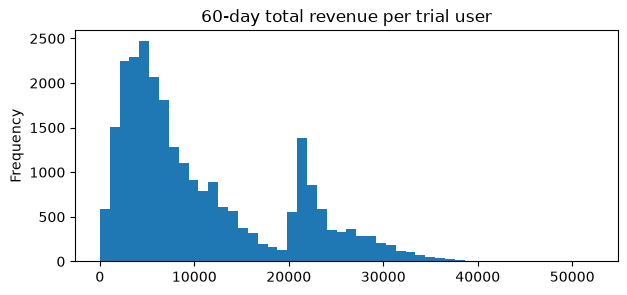

,A 평균(원),B 평균(원),차이(원),상대 차이(%),부트스트랩 95% CI 하한,부트스트랩 95% CI 상한,Welch t p-value,유의
지표,,,,,,,,
60일 총매출,10895.6,10517.4,-378.2,-3.5,-577.2,-165.2,0.0,✅
└ 패스 매출,5011.5,4895.9,-115.6,-2.3,-308.2,81.4,0.2,-
└ 코인 매출,5884.2,5621.6,-262.6,-4.5,-359.3,-165.5,0.0,✅


In [14]:
from scipy.stats import ttest_ind

trial_df = user_df[user_df["start_trial"] == 1]

print(trial_df["total_rev"].describe().round(0))
print(f"총매출 0원 비율: {(trial_df['total_rev'] == 0).mean():.2%}")
print(f"패스 매출 0원 비율: {(trial_df['pass_rev'] == 0).mean():.2%}")

trial_df["total_rev"].plot(kind="hist", bins=50, figsize=(7, 3),
                           title="60-day total revenue per trial user")
plt.show()


N_BOOT = 2000
rng = np.random.default_rng(42)

def compare_means(name, df, col):
    """B - A 평균 차이: Welch t-검정과 부트스트랩 95% CI"""
    a = df.loc[df["variant"] == "A", col].to_numpy()
    b = df.loc[df["variant"] == "B", col].to_numpy()
    diff = b.mean() - a.mean()

    # Welch t-검정 (두 그룹 분산이 달라도 되는 t-검정)
    t_p = ttest_ind(b, a, equal_var=False).pvalue

    # 부트스트랩: 그룹별로 복원 추출 → 평균 차이를 N_BOOT번 계산
    boot = np.array([
        rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()
        for _ in range(N_BOOT)
    ])
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    return {
        "지표": name,
        "A 평균(원)": a.mean(),
        "B 평균(원)": b.mean(),
        "차이(원)": diff,
        "상대 차이(%)": diff / a.mean() * 100,
        "부트스트랩 95% CI 하한": ci_low,
        "부트스트랩 95% CI 상한": ci_high,
        "Welch t p-value": t_p,
        "유의": "✅" if (ci_low > 0 or ci_high < 0) else "-",   # CI가 0을 포함하지 않으면 유의
    }

# ── 총매출 + 분해(패스 / 코인) ──
rev_results = pd.DataFrame([
    compare_means("60일 총매출", trial_df, "total_rev"),
    compare_means("  └ 패스 매출", trial_df, "pass_rev"),
    compare_means("  └ 코인 매출", trial_df, "coin_rev"),
]).set_index("지표")

rev_results.round(1)

In [15]:
# 노출자 전원 기준 1인당 패스 매출 (체험 안 한 유저는 0원)
itt_pass = pd.DataFrame([
    compare_means("노출자 1인당 패스 매출", user_df, "pass_rev")
]).set_index("지표")

itt_pass.round(1)

,A 평균(원),B 평균(원),차이(원),상대 차이(%),부트스트랩 95% CI 하한,부트스트랩 95% CI 상한,Welch t p-value,유의
지표,,,,,,,,
노출자 1인당 패스 매출,392.2,429.2,37.0,9.4,18.5,54.8,0.0,✅


### 라운드 4 결과

**4-2. 첫 달 해지율**
- A 26.82% vs B 28.34%, 차이 +1.52%p, p = 0.14
- 통계적으로 유의하지 않고, 출시 보류 기준(3%p 악화)에도 미달 → 가드레일 통과

**4-3. 60일 총매출 (체험 시작자 기준)**
- A 10,896원 vs B 10,517원, 차이 -378원 (-3.5%)
- 부트스트랩 95% CI가 0을 포함하지 않음, Welch t-검정 p = 0.0003 → 유의한 감소
- 두 방법의 결론이 일치 → 표본이 커서 t-검정의 정규성 가정도 문제없었던 것으로 판단
- 분해 결과: 패스 매출 차이는 유의하지 않고, 감소분 대부분이 코인 매출(-263원)에서 발생
- → 14일 패스 기간 동안 대기 건너뛰기·완결작 회차 코인 구매가 패스로 대체된 잠식효과로 추정

**4-4. 배정 기준 비교**
- 노출자 1인당 패스 매출: A 392원 vs B 429원, +37원 (+9.4%), 유의
- 배정 기준으로는 B가 패스 매출을 늘림 (결제자 증가 효과)
- 단, 체험 미시작자의 코인 기록이 수집되지 않아 노출자 기준 총매출은 비교 불가 → 데이터 수집 범위의 한계

**종합**
- 해지율: 가드레일 통과
- 매출: 체험 시작자 기준 총매출은 B가 유의하게 낮음, 원인은 코인 매출 감소
- 다만 체험 시작자 기준 비교에는 라운드 3의 선택 편향이 섞여 있음
  - B 체험 시작자에는 관심이 덜한 유저가 더 포함 → 1인당 매출이 낮게 나올 수 있음
  - 코인 감소가 "패스 잠식" 때문인지 "체험자 구성 변화" 때문인지 이 비교만으로는 분리 불가

**남은 의문 → 라운드 5**
- 전체 평균 뒤에 서로 다르게 반응한 집단이 숨어 있지 않은가
- 읽기 패턴(연재 추격형·완결 정주행형·탐색형)별로 B의 효과가 다른가

## 라운드 5. 세그먼트: 전체 평균이 가리고 있는 것은 없는가

### 라운드 4까지의 결론
- 노출자 기준 전환율: B 우세 (+0.24%p)
- 체험 시작자 기준 전환율: 차이 없음
- 체험 시작자 1인당 60일 총매출: B가 유의하게 낮음 (-378원), 원인은 코인 매출 감소

### 이번 라운드의 질문
- 전체로 보면 효과가 작거나 엇갈리는데, 그 안에서 B에 정반대로 반응한 집단이 섞여 있는 것은 아닌가
- 14일 체험이 누구에게는 득이고 누구에게는 독인가

### 왜 읽기 패턴으로 나누는가
- 체험 기간의 효과는 "체험 기간 동안 얼마나, 어떻게 읽는가"에 달려 있을 것
- 도메인 설정서 6장의 핵심 분석 축이 읽기 패턴
- 가설
  - 연재 추격형: 체험이 길수록 최신화 확인 습관이 생겨 유리
  - 완결 정주행형: 체험이 길면 무료로 완독하고 떠나서 불리
  - 탐색형: 차이 미미

---

### 5-1. 세그먼트 분류

**고민: 데이터에 세그먼트 컬럼이 없음**
- 실험 전 30일 열람 기록(pre30_*)으로 직접 분류해야 함
- 반드시 실험 전 기록을 사용 → 실험 후 행동으로 나누면 B의 영향을 받은 기준으로 집단을 나누게 되어 라운드 3의 선택 편향과 같은 문제가 생김

**분류 규칙 (도메인 설정서 6장 정의 기반)**

| 순서 | 조건 | 세그먼트 |
| --- | --- | --- |
| 1 | 실험 전 30일 열람 0회 | 활동 없음 |
| 2 | 무료 회차 비중 ≥ 50% | 탐색형 |
| 3 | 연재작 비중 ≥ 60% | 연재 추격형 |
| 4 | 완결작 비중 ≥ 60% (연재작 비중 ≤ 40%) | 완결 정주행형 |
| 5 | 그 외 | 혼합형 |

- 탐색형을 먼저 판정하는 이유: 탐색형은 연재·완결 비중보다 "무료 회차 위주"가 핵심 특징이라 다른 기준보다 우선
- 활동 없음: 가입 직후 노출된 신규 유저 등. 비중 검증 후 분석에서 제외 여부 판단

**검증**
- 분류 결과 비중을 도메인 설정서의 비중(연재 45%, 완결 30%, 탐색 25%)과 비교

---

### 5-2. 세그먼트별 효과 확인

**고민: 세그먼트마다 검정을 따로 하면 되지 않나**
- 검정을 여러 번 하면 우연히 "유의"가 나올 확률이 커짐 (다중 비교 문제)
  - 유의수준 5%로 검정 20번 → 아무 효과가 없어도 평균 1번은 유의하게 나옴
- 대응 1: Bonferroni 보정 → 유의수준을 검정 횟수로 나눔 (주요 세그먼트 3개 → 0.05 / 3 = 0.0167)
- 대응 2: 로지스틱 회귀의 상호작용항 → "B의 효과가 세그먼트마다 다른가"를 검정 한 번으로 확인

**후보 방법**

| 방법 | 묻는 것 | 판단 |
| --- | --- | --- |
| 세그먼트별 z-검정 | 각 세그먼트 안에서 B가 A와 다른가 | ✅ 효과 방향·크기 확인용. Bonferroni 보정 적용 |
| 상호작용항 로지스틱 회귀 | B의 효과가 세그먼트에 따라 다른가 | ✅ 세그먼트 간 차이의 공식 검정 |
| 세그먼트별 결과만 나열 | - | ✗ 우연한 차이와 진짜 차이를 구분할 수 없음 |

**어떤 기준으로 볼 것인가 (라운드 3 교훈)**
- 노출자 기준 전환율을 우선 확인 (배정 유지)
- 체험 시작자 기준 전환율, 매출은 진단용으로 함께 확인

**해석 시 주의**
- 세그먼트 분석은 실험 설계 시 주 가설이 아니었으므로 탐색적 결과로 해석 (설계서 7장)
- 결과는 후속 실험의 근거로 사용하고, 이것만으로 세그먼트별 출시를 결정하지는 않음

In [16]:
# 세그먼트 분류 

# ── 실험 전 30일 기록 붙이기 ──
PRE_COLS = ["pre30_serial_reads", "pre30_completed_reads", "pre30_free_reads"]
seg_df = user_df.merge(users[["user_id"] + PRE_COLS], on="user_id", how="left")

# ── 비중 계산 ──
total_reads = seg_df["pre30_serial_reads"] + seg_df["pre30_completed_reads"]
seg_df["serial_share"] = seg_df["pre30_serial_reads"] / total_reads.replace(0, np.nan)
seg_df["free_share"] = seg_df["pre30_free_reads"] / total_reads.replace(0, np.nan)
# replace(0, np.nan): 열람이 0회면 0으로 나누기 오류 대신 빈 값

# ── 분류 규칙 (위에서부터 먼저 맞는 조건 적용) ──
SEGMENT_RULES = [
    (total_reads == 0,              "활동 없음"),
    (seg_df["free_share"] >= 0.5,   "탐색형"),
    (seg_df["serial_share"] >= 0.6, "연재 추격형"),
    (seg_df["serial_share"] <= 0.4, "완결 정주행형"),
]
seg_df["segment"] = np.select([c for c, _ in SEGMENT_RULES],
                              [s for _, s in SEGMENT_RULES],
                              default="혼합형")

# ── 검증: 도메인 설정서 비중과 비교 ──
seg_share = (seg_df["segment"].value_counts(normalize=True) * 100).round(1)
domain_share = pd.Series({"연재 추격형": 45, "완결 정주행형": 30, "탐색형": 25})

pd.DataFrame({"분류 결과(%)": seg_share, "도메인 설정(%)": domain_share})

,분류 결과(%),도메인 설정(%)
연재 추격형,41.0,45.0
완결 정주행형,28.8,30.0
탐색형,23.0,25.0
혼합형,6.4,NaN
활동 없음,0.8,NaN


In [17]:
# 세그먼트 × 그룹 요약표

MAIN_SEGMENTS = ["연재 추격형", "완결 정주행형", "탐색형"]

seg_summary = (seg_df
    .groupby(["segment", "variant"])
    .agg(노출자=("user_id", "size"),
         체험시작률=("start_trial", "mean"),
         노출기준전환율=("converted", "mean"))
    .unstack("variant"))

# 체험 시작자 기준 지표
trial_seg = (seg_df[seg_df["start_trial"] == 1]
    .groupby(["segment", "variant"])
    .agg(체험시작자기준전환율=("converted", "mean"),
         총매출_원=("total_rev", "mean"))
    .unstack("variant"))

seg_summary = seg_summary.join(trial_seg)
rate_cols = ["체험시작률", "노출기준전환율", "체험시작자기준전환율"]
seg_summary.loc[:, rate_cols] = seg_summary.loc[:, rate_cols] * 100

seg_summary.loc[MAIN_SEGMENTS].round(2)

노출자         체험시작률        노출기준전환율       체험시작자기준전환율            총매출_원  \
variant      A      B      A      B       A     B          A      B         A   
segment                                                                         
연재 추격형   64534  64631   6.82   7.72    2.02  2.77      29.65  35.85  13378.60   
완결 정주행형  45268  45347  11.68  13.11    3.90  3.42      33.36  26.13  10632.51   
탐색형      36311  36240   4.70   5.02    0.74  0.91      15.82  18.04   5323.26   

                   
variant         B  
segment            
연재 추격형   14227.02  
완결 정주행형   8909.94  
탐색형       5362.60

In [18]:
# 세그먼트별 검정 

ALPHA_BONF = ALPHA / len(MAIN_SEGMENTS)     # 0.05 / 3 = 0.0167

rows = []
for seg in MAIN_SEGMENTS:
    s = seg_df[seg_df["segment"] == seg]
    exp_n   = s.groupby("variant")["user_id"].count()
    trial_n = s.groupby("variant")["start_trial"].sum()
    paid_n  = s.groupby("variant")["converted"].sum()

    for name, succ, n in [("노출 기준 전환율", paid_n, exp_n),
                          ("체험 시작자 기준 전환율", paid_n, trial_n)]:
        r = two_prop_test(name, succ["A"], n["A"], succ["B"], n["B"])
        r["세그먼트"] = seg
        r["유의(보정)"] = "✅" if r["p-value"] < ALPHA_BONF else "-"
        rows.append(r)

seg_tests = (pd.DataFrame(rows)
             .set_index(["세그먼트", "지표"])
             [["A(%)", "B(%)", "차이(%p)", "95% CI 하한(%p)", "95% CI 상한(%p)",
               "p-value", "유의(보정)"]])
seg_tests.round(3)

A(%)    B(%)  차이(%p)  95% CI 하한(%p)  95% CI 상한(%p)  \
세그먼트    지표                                                                    
연재 추격형  노출 기준 전환율       2.022   2.766   0.744          0.578          0.911   
        체험 시작자 기준 전환율  29.646  35.846   6.200          4.305          8.095   
완결 정주행형 노출 기준 전환율       3.897   3.425  -0.472         -0.717         -0.228   
        체험 시작자 기준 전환율  33.365  26.132  -7.233         -8.925         -5.541   
탐색형     노출 기준 전환율       0.744   0.905   0.162          0.030          0.293   
        체험 시작자 기준 전환율  15.817  18.042   2.225         -0.249          4.699   

                       p-value 유의(보정)  
세그먼트    지표                             
연재 추격형  노출 기준 전환율        0.000      ✅  
        체험 시작자 기준 전환율    0.000      ✅  
완결 정주행형 노출 기준 전환율        0.000      ✅  
        체험 시작자 기준 전환율    0.000      ✅  
탐색형     노출 기준 전환율        0.016      ✅  
        체험 시작자 기준 전환율    0.079      -

In [19]:
# 상호작용항 로지스틱 회귀

import statsmodels.formula.api as smf
from scipy.stats import chi2

main_df = seg_df[seg_df["segment"].isin(MAIN_SEGMENTS)]

# 연재 추격형을 기준(reference)으로 두고, B의 효과가 다른 세그먼트에서 얼마나 달라지는지 확인
formula_full = "converted ~ C(variant) * C(segment, Treatment('연재 추격형'))"
formula_base = "converted ~ C(variant) + C(segment, Treatment('연재 추격형'))"  # 상호작용 없음

model_full = smf.logit(formula_full, data=main_df).fit(disp=0)
model_base = smf.logit(formula_base, data=main_df).fit(disp=0)

# 우도비 검정: 상호작용항을 넣었을 때 모델이 유의하게 나아지는가
# = "B의 효과가 세그먼트마다 다른가"를 검정 한 번으로 확인
lr_stat = 2 * (model_full.llf - model_base.llf)
lr_p = chi2.sf(lr_stat, df=len(MAIN_SEGMENTS) - 1)
print(f"상호작용 우도비 검정: χ² = {lr_stat:.1f}, p = {lr_p:.2e}")

model_full.summary().tables[1]

상호작용 우도비 검정: χ² = 81.4, p = 2.10e-18


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-3.8806,0.028,-138.760,0.000,-3.935,-3.826
C(variant)[T.B],0.3210,0.037,8.713,0.000,0.249,0.393
"C(segment, Treatment('연재 추격형'))[T.완결 정주행형]",0.6753,0.037,18.231,0.000,0.603,0.748
"C(segment, Treatment('연재 추격형'))[T.탐색형]",-1.0134,0.067,-15.085,0.000,-1.145,-0.882
"C(variant)[T.B]:C(segment, Treatment('연재 추격형'))[T.완결 정주행형]",-0.4551,0.051,-8.901,0.000,-0.555,-0.355
"C(variant)[T.B]:C(segment, Treatment('연재 추격형'))[T.탐색형]",-0.1228,0.090,-1.359,0.174,-0.300,0.054


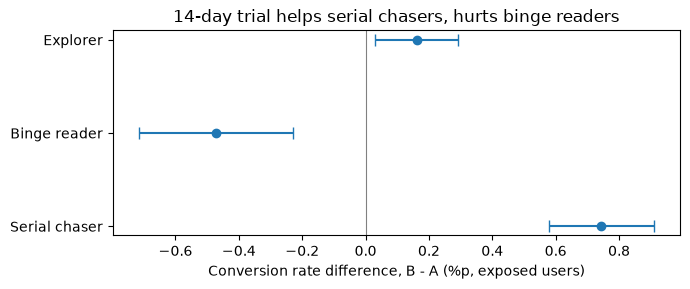

In [20]:
# 세그먼트별 효과 그래프 

plot_df = seg_tests.xs("노출 기준 전환율", level="지표").loc[MAIN_SEGMENTS]
seg_en = {"연재 추격형": "Serial chaser", "완결 정주행형": "Binge reader", "탐색형": "Explorer"}

fig, ax = plt.subplots(figsize=(7, 3))
y = range(len(plot_df))
ax.errorbar(plot_df["차이(%p)"], y,
            xerr=[plot_df["차이(%p)"] - plot_df["95% CI 하한(%p)"],
                  plot_df["95% CI 상한(%p)"] - plot_df["차이(%p)"]],
            fmt="o", capsize=4)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_yticks(list(y))
ax.set_yticklabels([seg_en[s] for s in plot_df.index])
ax.set_xlabel("Conversion rate difference, B - A (%p, exposed users)")
ax.set_title("14-day trial helps serial chasers, hurts binge readers")
plt.tight_layout()
plt.show()

### 라운드 5 결과

**5-1. 세그먼트 분류**
- 연재 추격형 41.0%, 완결 정주행형 28.8%, 탐색형 23.0%, 혼합형 6.4%, 활동 없음 0.8%
- 주요 3개 세그먼트 비중이 도메인 설정(45/30/25%)과 2~4%p 이내로 일치 → 분류 규칙 타당

**5-2. 세그먼트별 효과 (노출 기준 전환율, Bonferroni 보정 유의수준 0.0167)**
- 연재 추격형: +0.75%p, 유의 → 14일 체험이 유리
- 완결 정주행형: -0.47%p, 유의 → 14일 체험이 불리
- 탐색형: +0.16%p, 경계선상 유의
- 상호작용 우도비 검정 p < 0.001 → B의 효과가 세그먼트마다 다르다는 것이 통계적으로 확인됨

**체험 시작자 기준·매출로 본 진단**
- 연재 추격형: 체험 후 전환 +6.2%p, 1인당 총매출 13,382원 → 14,228원 (+846원)
- 완결 정주행형: 체험 후 전환 -7.2%p, 1인당 총매출 10,634원 → 8,909원 (-1,725원)
- → 라운드 4에서 본 총매출 감소는 대부분 완결 정주행형에서 발생

**해석**
- 연재 추격형: 체험 기간이 길수록 매일 최신화를 확인하는 습관이 형성되어 전환이 늘어난 것으로 추정
- 완결 정주행형: 14일이면 체험 중 완결작을 무료로 다 읽고 결제 없이 떠나는 것으로 추정 → 다음 단계에서 체험 중 완독 여부로 확인 가능
- 전체 평균에서 효과가 작게 보인 이유: 두 큰 세그먼트의 효과가 서로 반대 방향이라 상쇄됨

**주의**
- 세그먼트 분석은 탐색적 결과. 세그먼트별 차등 적용은 후속 실험으로 검증 필요

**남은 질문 → 라운드 6**
- 이 결과를 종합하면 7일과 14일 중 무엇을 출시해야 하는가

In [21]:
summary = pd.DataFrame([
    # 구분, 지표, 결과, 유의, 판단
    ["점검", "SRM", "A 157,461 vs B 157,461", "p = 1.0", "✅ 통과"],
    ["점검", "사전 균형", "|SMD| < 0.01", "-", "✅ 통과"],
    ["주요", "체험 시작자 기준 전환율", f"{test_results.loc['체험 시작 기준 전환율', '차이(%p)']:+.2f}%p",
     f"p = {test_results.loc['체험 시작 기준 전환율', 'p-value']:.2f}", "차이 없음"],
    ["보조", "체험 시작률", f"{test_results.loc['체험 시작률', '차이(%p)']:+.2f}%p",
     "p < 0.001", "B 우세 → 선택 편향"],
    ["보조", "노출 기준 전환율", f"{test_results.loc['노출 기준 전환율', '차이(%p)']:+.2f}%p",
     "p < 0.001", "B 우세"],
    ["가드레일", "첫 달 해지율", f"{churn_result.loc['첫 달 해지율', '차이(%p)']:+.2f}%p",
     f"p = {churn_result.loc['첫 달 해지율', 'p-value']:.2f}", "✅ 통과 (기준 3%p)"],
    ["가드레일", "60일 총매출 (체험 시작자)", f"{rev_results.loc['60일 총매출', '차이(원)']:+,.0f}원",
     "CI 0 미포함", "⚠️ B 유의 감소"],
    ["세그먼트", "상호작용 (B 효과 × 세그먼트)", "연재 +, 완결 −", "p < 0.001", "효과 반대 방향"],
], columns=["구분", "지표", "B − A", "유의성", "판단"])

summary

,구분,지표,B − A,유의성,판단
0,점검,SRM,"A 157,461 vs B 157,461",p = 1.0,✅ 통과
1,점검,사전 균형,|SMD| < 0.01,-,✅ 통과
2,주요,체험 시작자 기준 전환율,-0.42%p,p = 0.45,차이 없음
3,보조,체험 시작률,+0.94%p,p < 0.001,B 우세 → 선택 편향
4,보조,노출 기준 전환율,+0.24%p,p < 0.001,B 우세
5,가드레일,첫 달 해지율,+1.52%p,p = 0.14,✅ 통과 (기준 3%p)
6,가드레일,60일 총매출 (체험 시작자),-378원,CI 0 미포함,⚠️ B 유의 감소
7,세그먼트,상호작용 (B 효과 × 세그먼트),"연재 +, 완결 −",p < 0.001,효과 반대 방향


In [22]:
# ── 세그먼트 비중과, 세그먼트 × 그룹별 실제 관찰값 ──
seg_share = seg_df["segment"].value_counts(normalize=True)
seg_rates = (seg_df.groupby(["segment", "variant"])[["converted", "pass_rev"]]
             .mean().unstack("variant"))

# ── 시나리오: 세그먼트마다 어떤 체험 기간(A/B)을 적용할지 ──
scenarios = {
    "전체 7일 (A)":            {s: "A" for s in seg_share.index},
    "전체 14일 (B)":           {s: "B" for s in seg_share.index},
    "차등: 연재 추격형만 14일": {s: ("B" if s == "연재 추격형" else "A") for s in seg_share.index},
}

rows = []
for name, plan in scenarios.items():
    # 세그먼트 비중 × 그 세그먼트에 적용한 그룹의 관찰값을 모두 더함
    conv = sum(seg_share[s] * seg_rates.loc[s, ("converted", plan[s])] for s in seg_share.index)
    rev = sum(seg_share[s] * seg_rates.loc[s, ("pass_rev", plan[s])] for s in seg_share.index)
    rows.append({"시나리오": name, "노출 기준 전환율(%)": conv * 100, "노출자 1인당 패스 매출(원)": rev})

scenario_df = pd.DataFrame(rows).set_index("시나리오")
base_row = scenario_df.loc["전체 7일 (A)"]
scenario_df["전환율 차이(%p, vs A)"] = scenario_df["노출 기준 전환율(%)"] - base_row["노출 기준 전환율(%)"]
scenario_df["패스 매출 차이(원, vs A)"] = scenario_df["노출자 1인당 패스 매출(원)"] - base_row["노출자 1인당 패스 매출(원)"]

scenario_df.round(2)

,노출 기준 전환율(%),노출자 1인당 패스 매출(원),"전환율 차이(%p, vs A)","패스 매출 차이(원, vs A)"
시나리오,,,,
전체 7일 (A),2.29,392.31,0.00,0.00
전체 14일 (B),2.53,429.14,0.24,36.83
차등: 연재 추격형만 14일,2.59,448.69,0.31,56.38


## 최종 결론

### 권고
**B(14일) 전면 출시는 하지 않고 A(7일)를 유지하되, 읽기 패턴별 차등 체험 기간을 후속 실험으로 검증**

### 근거
1. 설계서 주요 지표(체험 시작자 기준 전환율)는 차이 없음 (-0.42%p, p = 0.45)
2. 배정 기준(노출자) 전환율은 B가 높으나 (+0.24%p), 체험 시작자 1인당 60일 총매출이 유의하게 감소 (-378원, -3.5%)
3. 매출 감소는 대부분 완결 정주행형에서 발생 (1인당 -1,725원), 원인은 코인 매출 감소
4. 세그먼트별 효과가 반대 방향 (상호작용 p < 0.001)
   - 연재 추격형: 14일 체험이 전환 +0.75%p, 1인당 매출 +846원
   - 완결 정주행형: 14일 체험이 전환 -0.47%p, 1인당 매출 -1,725원
5. 설계서 8장 기준: 어느 해석으로도 B 전면 출시 조건 불충족, "세그먼트별 효과 반대 → 차등 체험 후속 실험"에 해당

### 후속 실험 제안
- 가설: 연재 추격형에게만 14일, 나머지에게는 7일 체험을 제공하면 전환율과 매출이 모두 개선된다
- 예상 효과 (본 실험 기반 탐색적 추정): 노출 기준 전환율 +0.31%p, 노출자 1인당 패스 매출 +57원 (전체 7일 대비)
- 설계 시 반영할 점
  - 주요 지표: 노출자 기준 전환율 (선택 편향 방지)
  - 코인 매출을 노출자 전원 기준으로 수집 (본 실험에서는 체험 시작자만 수집되어 노출자 기준 총매출 비교 불가)
  - 세그먼트 분류는 실험 전 30일 기록 기준으로 배정 시점에 고정

### 한계
- 세그먼트 분석과 차등 시나리오는 탐색적 결과로, 사전 가설이 아니었음
- 코인 매출이 체험 시작자에 대해서만 수집되어, 배정 기준 총매출 효과는 확인하지 못함
- 체험 시작자 기준 비교(주요 지표, 매출 가드레일)에는 선택 편향이 섞여 있음

### 실험 설계 대비 변경 사항
- 노출 기록이 유실된 78명 제외 (실험군 확인 불가, 전체의 0.03%)
- 내부 테스트 계정 200명, 중복 결제 이벤트 66건 제외
- 판단 시 설계서 주요 지표와 함께 배정 기준(노출자) 전환율을 병행 검토 (라운드 3에서 발견한 선택 편향 때문)

### 회고: 다시 설계한다면
- 주요 지표를 노출자 기준 전환율로 설정
- 실험 결과가 체험 시작 여부에 좌우되는 구조임을 설계 단계에서 고려
- 가드레일 매출 지표도 노출자 기준으로 측정할 수 있도록 데이터 수집 범위 설계